# Tornado Activity in Cook County's South Suburbs

## 1. Introduction

Tornadoes are rare but dangerous in the Chicagoland area. This project examines where recent tornado reports in Cook County, Illinois have clustered, and whether the south suburban communities of Flossmoor, Homewood, Glenwood, and Chicago Heights have seen more tornado activity relative to the rest of the county. Understanding local hot spots helps emergency managers, utilities, and residents prioritize preparedness and warning outreach.

**Data and study window:** point-level tornado reports from the NOAA/NCEI Storm Events database (May 2024 – May 2025) and the Cook County boundary from the U.S. Census TIGER/Line 2025 county layer. Tornado start locations (BEGIN_LAT/LON) are treated as event points in WGS84.

**Method overview:**
1. Filter Storm Events to tornadoes within the Cook County boundary.
2. Assign each point to the nearest study town (within a 6 km threshold) or label it "Other Cook."
3. Summarize event counts and each town's share of the county total, and map the locations for visual context.

**Research question and hypothesis:**
1. **RQ1:** What fraction of Cook County tornadoes (2024–2025) occurred closest to the four study towns?
2. **H1:** Because storms in this region commonly track southwest to northeast across the south suburbs, we expect a modest concentration near the Flossmoor–Homewood–Glenwood–Chicago Heights corridor relative to the county as a whole.


In [1]:
import pandas as pd
import geopandas as gpd
from pathlib import Path
import numpy as np
from math import radians, sin, cos, asin, sqrt
import matplotlib.pyplot as plt
import fiona
from shapely.geometry import Point, shape, Polygon, MultiPolygon

DATA = Path("data")          
OUT  = Path("outputs")
OUT.mkdir(parents=True, exist_ok=True)

NOAA_CSV   = DATA / "storm_data_search_results.csv"
COUNTY_SHP = DATA / "cook_county.shp"


In [2]:
# Read NOAA Storm Events
events = pd.read_csv(NOAA_CSV, parse_dates=["BEGIN_DATE","END_DATE"])

events["BEGIN_LAT"] = pd.to_numeric(events["BEGIN_LAT"], errors="coerce")
events["BEGIN_LON"] = pd.to_numeric(events["BEGIN_LON"], errors="coerce")

events = events.dropna(subset=["BEGIN_LAT","BEGIN_LON"]).copy()


events = events[(events["BEGIN_DATE"] >= "2024-01-01") &
                (events["BEGIN_DATE"] <= "2025-12-31")].copy()

# Tornadoes only
events = events[events["EVENT_TYPE"].str.upper() == "TORNADO"].copy()

print("NOAA tornado rows (2024–2025) with coords:", len(events))
events.head(3)

NOAA tornado rows (2024–2025) with coords: 15


,EVENT_ID,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,BEGIN_TIME,EVENT_TYPE,MAGNITUDE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,...,END_LOCATION,END_DATE,END_TIME,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EVENT_NARRATIVE,EPISODE_NARRATIVE,ABSOLUTE_ROWNUMBER
72,1190857,COOK CO.,WESTERN SPRINGS,2024-07-14,2123,Tornado,,EF0,0,0,...,CICERO,2024-07-14,2133,41.8151,-87.8858,41.8519,-87.7518,A tornado with estimated peak winds of 75 mph ...,Thunderstorms developed during the evening of ...,73
73,1190858,COOK CO.,(MDW) CHICAGO MIDWAY AIRPORT,2024-07-14,2133,Tornado,,EF0,0,0,...,KENWOOD,2024-07-14,2143,41.7900,-87.7425,41.8178,-87.5923,A tornado with estimated peak winds of 85 mph ...,Thunderstorms developed during the evening of ...,74
78,1190866,COOK CO.,ENGLEWOOD,2024-07-14,2140,Tornado,,EF0,0,0,...,JACKSON PARK,2024-07-14,2144,41.7680,-87.6340,41.7814,-87.5683,A tornado with estimated peak winds of 80 mph ...,Thunderstorms developed during the evening of ...,79


In [3]:
# Read Cook County
cook_geom = None
with fiona.open(COUNTY_SHP) as src:
    for feat in src:
        props = feat["properties"]
        # Either GEOID or STATEFP/COUNTYFP will work
        if (props.get("GEOID") == "17031") or \
           (props.get("STATEFP") == "17" and str(props.get("COUNTYFP")).zfill(3) == "031"):
            cook_geom = shape(feat["geometry"])
            break

assert cook_geom is not None, "Cook County geometry not found. Check the shapefile."

minx, miny, maxx, maxy = cook_geom.bounds
print("Cook bounds:", (minx, miny, maxx, maxy))

Cook bounds: (-88.263641, 41.469705, -87.111162, 42.154292)


In [4]:
def in_cook(r):
    p = Point(r["BEGIN_LON"], r["BEGIN_LAT"])
    return cook_geom.contains(p)

events["in_cook"] = events.apply(in_cook, axis=1)
cook_events = events[events["in_cook"]].copy()

print("Tornadoes in Cook County:", len(cook_events), "of", len(events))
cook_events.head(2)

Tornadoes in Cook County: 14 of 15


,EVENT_ID,CZ_NAME_STR,BEGIN_LOCATION,BEGIN_DATE,BEGIN_TIME,EVENT_TYPE,MAGNITUDE,TOR_F_SCALE,DEATHS_DIRECT,INJURIES_DIRECT,...,END_DATE,END_TIME,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EVENT_NARRATIVE,EPISODE_NARRATIVE,ABSOLUTE_ROWNUMBER,in_cook
72,1190857,COOK CO.,WESTERN SPRINGS,2024-07-14,2123,Tornado,,EF0,0,0,...,2024-07-14,2133,41.8151,-87.8858,41.8519,-87.7518,A tornado with estimated peak winds of 75 mph ...,Thunderstorms developed during the evening of ...,73,True
73,1190858,COOK CO.,(MDW) CHICAGO MIDWAY AIRPORT,2024-07-14,2133,Tornado,,EF0,0,0,...,2024-07-14,2143,41.7900,-87.7425,41.8178,-87.5923,A tornado with estimated peak winds of 85 mph ...,Thunderstorms developed during the evening of ...,74,True


In [5]:
TOWNS = {
    "FLOSSMOOR":        (41.5417, -87.6848),
    "GLENWOOD":         (41.5448, -87.6120),
    "HOMEWOOD":         (41.5565, -87.6659),
    "CHICAGO HEIGHTS":  (41.5060, -87.6356),
}

def haversine(lat1, lon1, lat2, lon2):
    # returns kilometers
    dlat = radians(lat2-lat1)
    dlon = radians(lon2-lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return 2*6371*asin(sqrt(a))

centers = list(TOWNS.values())
labels  = list(TOWNS.keys())

def nearest_town(r, max_km=6.0):
    lat, lon = r["BEGIN_LAT"], r["BEGIN_LON"]
    dists = [haversine(lat, lon, c[0], c[1]) for c in centers]
    j = int(np.argmin(dists))
    return labels[j] if dists[j] <= max_km else "Other Cook"

cook_events["place"] = cook_events.apply(nearest_town, axis=1)

cook_total = len(cook_events)
counts = (cook_events["place"]
          .value_counts()
          .rename_axis("place")
          .reset_index(name="tornado_count")
          .sort_values("tornado_count", ascending=False))
counts["share_of_cook_%"] = (counts["tornado_count"]/cook_total*100).round(1)

counts

,place,tornado_count,share_of_cook_%
0,Other Cook,11,78.6
1,FLOSSMOOR,1,7.1
2,HOMEWOOD,1,7.1
3,GLENWOOD,1,7.1


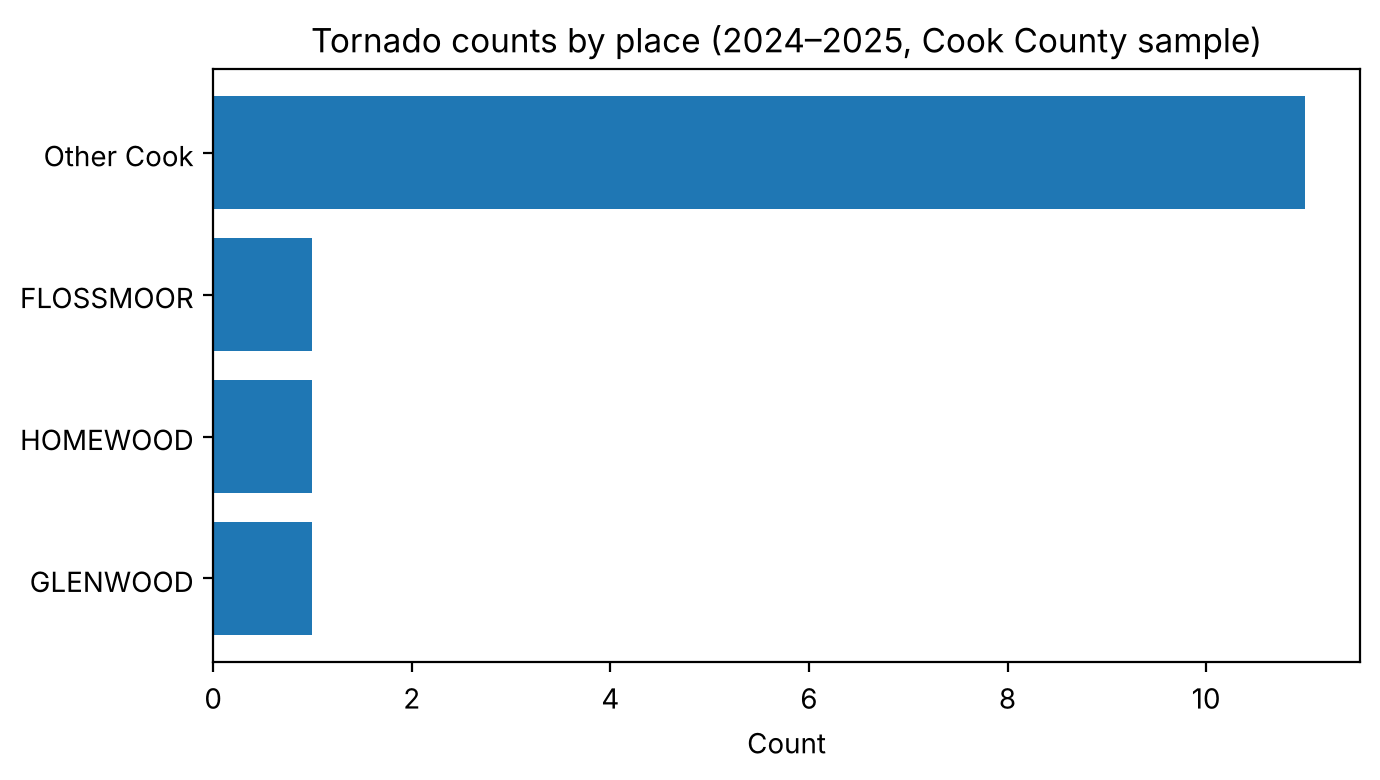

Wrote: outputs/tornado_counts_by_place.csv
Wrote: outputs/cook_tornado_points_2024_2025.csv
Wrote: outputs/tornado_counts_by_place.png


In [6]:
# Bar chart
plt.figure(figsize=(7,4))
plt.barh(counts["place"], counts["tornado_count"])
plt.title("Tornado counts by place (2024–2025, Cook County sample)")
plt.xlabel("Count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

counts.to_csv(OUT/"tornado_counts_by_place.csv", index=False)
cook_events.to_csv(OUT/"cook_tornado_points_2024_2025.csv", index=False)

plt.figure(figsize=(7,4))
plt.barh(counts["place"], counts["tornado_count"])
plt.title("Tornado counts by place (2024–2025, Cook County sample)")
plt.xlabel("Count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(OUT/"tornado_counts_by_place.png", dpi=150)
plt.close()

print("Wrote:", OUT/"tornado_counts_by_place.csv")
print("Wrote:", OUT/"cook_tornado_points_2024_2025.csv")
print("Wrote:", OUT/"tornado_counts_by_place.png")

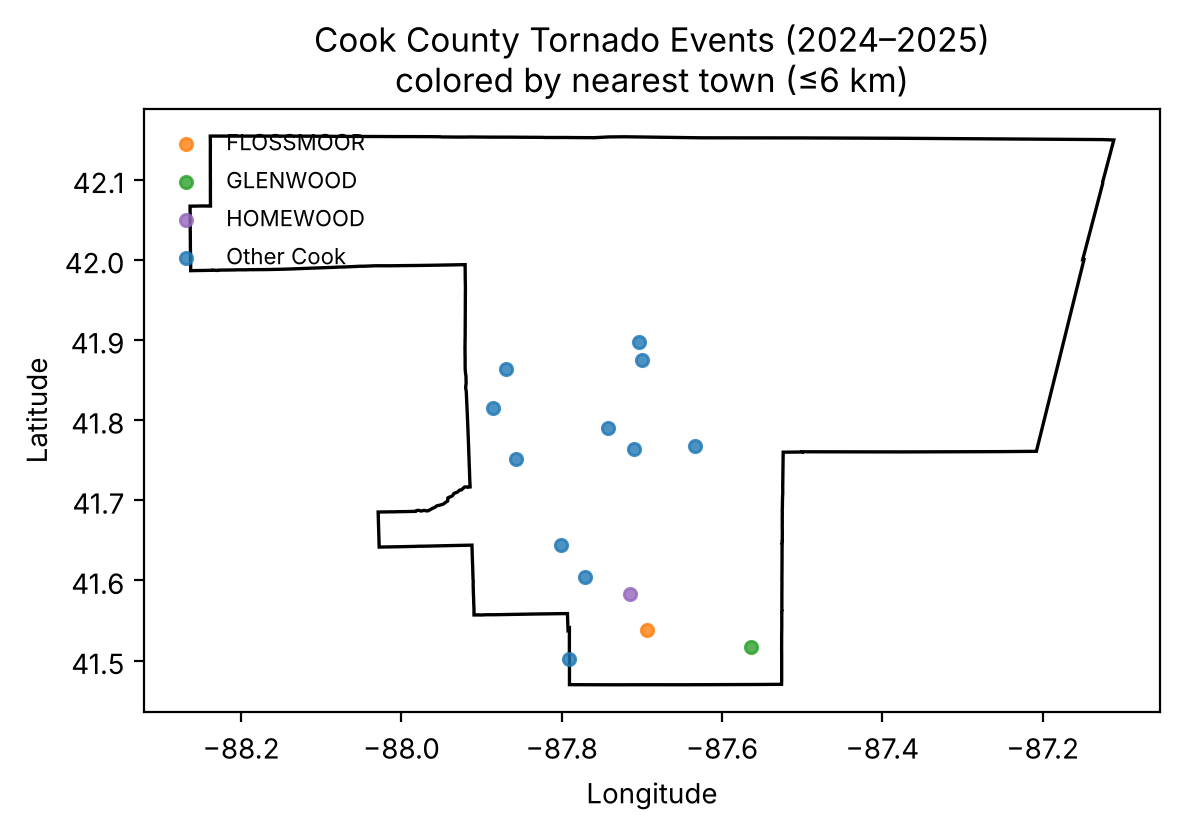

In [7]:
def polygon_patches(geom, **kwargs):
    patches = []
    if isinstance(geom, Polygon):
        patches.append(plt.Polygon(list(geom.exterior.coords), closed=True, **kwargs))
    elif isinstance(geom, MultiPolygon):
        for g in geom.geoms:
            patches += polygon_patches(g, **kwargs)
    return patches

plt.figure(figsize=(6,6))
for p in polygon_patches(cook_geom, fill=False, edgecolor="black", linewidth=1.2):
    plt.gca().add_patch(p)

palette = {"FLOSSMOOR":"tab:orange","GLENWOOD":"tab:green",
           "HOMEWOOD":"tab:purple","CHICAGO HEIGHTS":"tab:red",
           "Other Cook":"tab:blue"}

for place, sub in cook_events.groupby("place"):
    plt.scatter(sub["BEGIN_LON"], sub["BEGIN_LAT"], s=20, label=place,
                alpha=0.8, color=palette.get(place,"gray"))

minx, miny, maxx, maxy = cook_geom.bounds
padx, pady = (maxx-minx)*0.05, (maxy-miny)*0.05
plt.xlim(minx-padx, maxx+padx)
plt.ylim(miny-pady, maxy+pady)
plt.gca().set_aspect("equal","box")
plt.title("Cook County Tornado Events (2024–2025)\ncolored by nearest town (≤6 km)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.legend(loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## Results and limitations

- 14 of the 15 tornado reports in the search results fell inside the Cook County boundary.
- 3 of those 14 (about 21%) started within 6 km of a study town: one each near Flossmoor, Homewood, and Glenwood. None was within 6 km of Chicago Heights.
- The other 11 (about 79%) occurred elsewhere in the county.

**Limitations:** this covers about one year of data and only 14 events, so it is too small to establish a real geographic pattern. Results also depend on the 6 km distance threshold. A longer record (for example, 1950 to the present) and a comparison against each area's land share of the county would be needed to properly test H1.
